# Estimating the embodied emissions of buildings in Canada for Shahid's paper
Here I use RASMI sampler package to estimate embodied emissions in Canadian buildings:
- importing and querying the raw RASMI kg/m2 data
- linking it to LCA factors from Ecoinvent or any other desired LCA dataset
- performing bootstrapped MC sampling of emissions, based on building share of m2 (assume it remains unchanged)
- Multiply by the emission factors to get a value. Send to Shahid and then adjust for material emissions

## Import and initialize

In [120]:
# import normal package suite
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from rasmi_lca_v1 import *

In [121]:
rlca = RasmiLCA(rasmi_path='', factors_path='')

importing RASMI dataset...
   concrete ...
   brick ...
   wood ...
   steel ...
   glass ...
   plastics ...
   aluminum ...
   copper ...
importing lca factor dataset...
   concrete ...
   brick ...
   wood ...
   steel ...
   glass ...
   plastics ...
   aluminum ...
   copper ...


## Parameters
**Building type split** (assumed constant over time): NRCan Comprehensive Energy Use Database, Residential Sector Canada, Table 24, 2023 values ([link](https://oee.nrcan.gc.ca/corporate/statistics/neud/dpa/showTable.cfm?type=CP&sector=res&juris=ca&year=2023&rn=24)). In the source:
- `RS` (residential single-family) = single detached + single attached + mobile homes
- `RM` (residential multi-family) = apartments

**Structural system** of new construction (`C` concrete, `M` masonry, `S` steel, `T` timber):
- `RS`: single-family housing in Canada is overwhelmingly light wood frame.
- `RM`: StatCan 2021 Census Profile (structural type of dwelling): assumed primarily concrete structures, which some others mxed.

**Demo/replacement rate**: assume a cohort-based MFA flow where x% of stock per year is demolished (https://www.statcan.gc.ca/o1/en/plus/3896-boom-goes-dynamiteand-conversions)

In [122]:
# sampling params
rlca.n = 20000
rlca.seed = 100
geo = 'OECD_CAN'

# NRCan CEUD Residential Canada Table 24, 2023 floor space by building type (million m2)
ceud_floor_2023 = pd.Series({'single_detached': 1456.0, 'single_attached': 289.7, 'apartments': 579.9, 'mobile_homes': 27.5})
type_map = {'single_detached': 'RS', 'single_attached': 'RS', 'mobile_homes': 'RS', 'apartments': 'RM'}
type_shares = ceud_floor_2023.groupby(type_map).sum()
type_shares = type_shares / type_shares.sum()

# structural system mix of new construction for each RASMI function.
struct_weights = {
    'RS': {'C': 0.25, 'M': 0.25, 'S': 0.25, 'T': 0.25},
    'RM': {'C': 0.25, 'M': 0.25, 'S': 0.25, 'T': 0.25},
}

# truncation error adjustment
btm_up_adj = 1.3

# fraction of previous year's stock demolished and replaced each year
demo_rate = 0.01

# first year counted in cumulative emissions
cum_start = 2026

type_shares

RM    0.246441
RS    0.753559
dtype: float64

## Floor space
Total residential floor space (million m2) from sheet 2 of `shahid_floorspace.xlsx`

In [98]:
fs = pd.read_excel('data/shahid_casestudy_data/shahid_floorspace.xlsx', sheet_name=1, header=None, nrows=2)
fs = fs.iloc[:, 1:].T.dropna()

floor = pd.Series(fs[1].astype(float).values, index=fs[0].astype(int).values, name='floor_Mm2')
floor.index.name = 'year'
floor.tail()

year
2046    3111.851997
2047    3145.781012
2048    3179.710027
2049    3213.639042
2050    3247.568057
Name: floor_Mm2, dtype: float64

## New floor area
New construction each year = change in stock + demolition replacement:

$S_{new,t} = \max(S_t - S_{t-1}, 0) + r_{demo} F_{t-1}$


In [99]:
d_stock = floor.diff()
print('years with negative stock change (set to 0):', d_stock[d_stock < 0].index.tolist())

new_area = (d_stock.clip(lower=0) + demo_rate * floor.shift(1)).dropna()

# split by RASMI function (million m2/yr)
new_area_type = pd.DataFrame({f: new_area * type_shares[f] for f in ['RS', 'RM']})
assert (new_area_type >= 0).all().all()
new_area_type.tail()

years with negative stock change (set to 0): [2026]


,RS,RM
year,,
2046,37.164504,12.154126
2047,37.292342,12.195933
2048,37.420179,12.237741
2049,37.548017,12.279548
2050,37.675854,12.321356


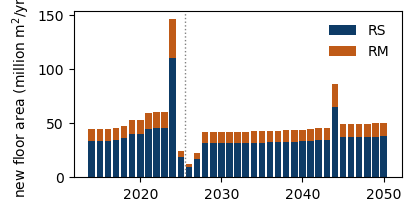

In [100]:
clr = {'total': 'k', 'RS': '#0D3B66', 'RM': '#BF5A17'}

fig, ax = plt.subplots(figsize=(4, 2), constrained_layout=True)
ax.bar(new_area_type.index, new_area_type['RS'], color=clr['RS'], label='RS')
ax.bar(new_area_type.index, new_area_type['RM'], bottom=new_area_type['RS'], color=clr['RM'], label='RM')
ax.axvline(cum_start - 0.5, color='grey', ls=':', lw=1)
ax.set(ylabel='new floor area (million m$^2$/yr)')
ax.legend(frameon=False)

## Sample emission intensities
Sample kgCO2e/m2 for each function and structure with `sample_and_calc`, then build the structure-weighted mixture: each MC draw takes its value from a structure picked with probability `struct_weights`.

In [106]:
structures = ['C', 'M', 'S', 'T']

# kgCO2e/m2 samples for each function and structure, adjust for bottom-up
ef_struct = {f: {s: rlca.sample_and_calc(f, s, geo)*btm_up_adj for s in structures} for f in struct_weights}

# structure-weighted mixture
rng = np.random.default_rng(rlca.seed)
ef = {}
for f, w in struct_weights.items():
    pick = rng.choice(structures, size=rlca.n, p=[w[s] for s in structures])
    ef[f] = np.select([pick == s for s in structures], [ef_struct[f][s] for s in structures])

In [107]:
def pctl(x, axis=None):
    return {'p5': np.percentile(x, 5, axis=axis), 'p50': np.percentile(x, 50, axis=axis),
            'p95': np.percentile(x, 95, axis=axis), 'mean': np.mean(x, axis=axis)}

ef_rows = {(f, s): pctl(ef_struct[f][s]) for f in ef_struct for s in structures}
ef_rows.update({(f, 'mix'): pctl(ef[f]) for f in ef})
ef_summary = pd.DataFrame(ef_rows).T.sort_index()
# bottom_up adjustment
ef_summary.round(1)

p5    p50     p95   mean
RM C    289.4  518.6  1096.5  582.6
   M    201.7  486.2   981.2  527.8
   S    116.5  415.8   764.2  418.2
   T    103.6  267.0   612.4  324.3
   mix  131.4  416.3   932.4  460.5
RS C    196.8  419.2   745.5  438.2
   M    278.2  570.8  1067.9  602.5
   S    193.0  567.2   858.6  548.7
   T    114.7  177.4   404.2  206.5
   mix  137.1  429.7   853.5  448.3

[(0.0, 100.0), Text(0, 0.5, 'percentile')]

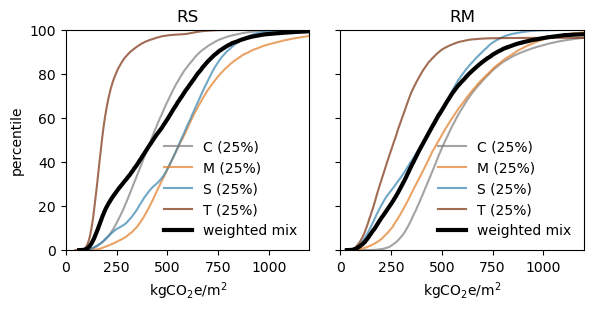

In [108]:
s_clrs = {'C': "#7D7D7D", 'M': '#E27D27', 'S': '#3584B1', 'T': '#7A2E0C'}

fig, ax = plt.subplots(1, 2, figsize=(6, 3), constrained_layout=True, sharey=True)
for a, f in zip(ax, ['RS', 'RM']):
    for s in structures:
        x = np.sort(ef_struct[f][s])
        a.plot(x, np.linspace(0, 100, len(x), endpoint=False), lw=1.5, alpha=0.7, color=s_clrs[s], label=f'{s} ({struct_weights[f][s]:.0%})')
    x = np.sort(ef[f])
    a.plot(x, np.linspace(0, 100, len(x), endpoint=False), lw=3, color='k', label='weighted mix')
    a.set(title=f, xlim=[0, 1200], xlabel='kgCO$_2$e/m$^2$')
    a.legend(frameon=False)
ax[0].set(ylim=[0, 100], ylabel='percentile')

## Embodied emissions
Annual emissions (Mt CO2e) = new floor area x sampled intensity, summed over `RS` and `RM`. The same MC draw is used in every year, so intensity uncertainty is fully correlated over time. Cumulative emissions are summed from `cum_start`.

In [109]:
years = new_area_type.index

# Mt CO2e per year for each draw: Mm2 * 1e6 m2/Mm2 * kgCO2e/m2 / 1e9 kg/Mt
em = {f: np.outer(new_area_type[f].values, ef[f]) * 1e6 / 1e9 for f in ef}
em['total'] = em['RS'] + em['RM']

# cumulative from cum_start
cum_mask = years >= cum_start
em_cum = {k: v[cum_mask].cumsum(axis=0) for k, v in em.items()}

annual = pd.concat({k: pd.DataFrame(pctl(v, axis=1), index=years) for k, v in em.items()}, axis=1)
cumulative = pd.concat({k: pd.DataFrame(pctl(v, axis=1), index=years[cum_mask]) for k, v in em_cum.items()}, axis=1)
annual.round(2)

RS                         RM                       total         \
         p5    p50    p95   mean    p5    p50    p95   mean     p5    p50   
year                                                                        
2014   4.59  14.37  28.54  14.99  1.44   4.55  10.20   5.04   8.14  19.41   
2015   4.64  14.54  28.89  15.17  1.45   4.61  10.32   5.10   8.25  19.65   
2016   4.61  14.45  28.70  15.07  1.44   4.58  10.25   5.06   8.19  19.52   
2017   4.69  14.68  29.17  15.32  1.47   4.65  10.42   5.15   8.32  19.84   
2018   4.93  15.45  30.68  16.12  1.54   4.89  10.96   5.41   8.76  20.87   
2019   5.43  17.00  33.76  17.73  1.70   5.38  12.06   5.96   9.64  22.96   
2020   5.51  17.25  34.27  18.00  1.73   5.47  12.25   6.05   9.78  23.31   
2021   6.10  19.10  37.95  19.93  1.91   6.05  13.56   6.70  10.83  25.81   
2022   6.20  19.43  38.60  20.27  1.94   6.16  13.79   6.81  11.02  26.25   
2023   6.21  19.46  38.65  20.30  1.95   6.16  13.81   6.82  11.03  26.29   
2024  15.09  47.26  93.87  49.31  4.73  14.97  33.54  16.57  26.79  63.85   
2025   2.51   7.87  15.64   8.21  0.79   2.49   5.59   2.76   4.46  10.63   
2026   1.29   4.05   8.04   4.22  0.40   1.28   2.87   1.42   2.29   5.47   
2027   2.29   7.16  14.23   7.48  0.72   2.27   5.08   2.51   4.06   9.68   
2028   4.33  13.58  26.98  14.17  1.36   4.30   9.64   4.76   7.70  18.35   
2029   4.32  13.54  26.89  14.12  1.35   4.29   9.61   4.75   7.67  18.29   
2030   4.32  13.54  26.89  14.12  1.35   4.29   9.61   4.74   7.67  18.29   
2031   4.33  13.56  26.93  14.15  1.36   4.30   9.62   4.75   7.69  18.32   
2032   4.34  13.61  27.03  14.20  1.36   4.31   9.66   4.77   7.72  18.39   
2033   4.37  13.69  27.18  14.28  1.37   4.34   9.71   4.80   7.76  18.49   
2034   4.39  13.74  27.29  14.34  1.37   4.35   9.75   4.82   7.79  18.56   
2035   4.39  13.76  27.34  14.36  1.38   4.36   9.77   4.83   7.80  18.60   
2036   4.41  13.82  27.45  14.42  1.38   4.38   9.81   4.84   7.84  18.67   
2037   4.44  13.90  27.61  14.50  1.39   4.40   9.86   4.87   7.88  18.78   
2038   4.47  14.01  27.83  14.62  1.40   4.44   9.94   4.91   7.94  18.93   
2039   4.51  14.14  28.08  14.75  1.41   4.48  10.03   4.96   8.01  19.10   
2040   4.56  14.28  28.37  14.90  1.43   4.52  10.14   5.01   8.10  19.29   
2041   4.61  14.43  28.67  15.06  1.44   4.57  10.24   5.06   8.18  19.50   
2042   4.66  14.61  29.02  15.24  1.46   4.63  10.37   5.12   8.28  19.73   
2043   4.72  14.78  29.36  15.42  1.48   4.68  10.49   5.18   8.38  19.97   
2044   8.91  27.92  55.46  29.13  2.79   8.85  19.81   9.79  15.83  37.72   
2045   5.08  15.91  31.61  16.60  1.59   5.04  11.29   5.58   9.02  21.50   
2046   5.10  15.97  31.72  16.66  1.60   5.06  11.33   5.60   9.05  21.57   
2047   5.11  16.02  31.83  16.72  1.60   5.08  11.37   5.62   9.08  21.65   
2048   5.13  16.08  31.94  16.78  1.61   5.09  11.41   5.64   9.11  21.72   
2049   5.15  16.13  32.05  16.83  1.61   5.11  11.45   5.66   9.15  21.79   
2050   5.17  16.19  32.15  16.89  1.62   5.13  11.49   5.67   9.18  21.87   

                     
         p95   mean  
year                 
2014   35.04  20.02  
2015   35.47  20.27  
2016   35.24  20.14  
2017   35.82  20.47  
2018   37.68  21.53  
2019   41.46  23.69  
2020   42.09  24.05  
2021   46.60  26.63  
2022   47.39  27.09  
2023   47.46  27.12  
2024  115.27  65.88  
2025   19.20  10.97  
2026    9.87   5.64  
2027   17.48   9.99  
2028   33.12  18.93  
2029   33.02  18.87  
2030   33.02  18.87  
2031   33.07  18.90  
2032   33.20  18.97  
2033   33.38  19.08  
2034   33.52  19.15  
2035   33.57  19.19  
2036   33.71  19.26  
2037   33.90  19.37  
2038   34.17  19.53  
2039   34.48  19.70  
2040   34.83  19.91  
2041   35.21  20.12  
2042   35.63  20.36  
2043   36.05  20.60  
2044   68.10  38.92  
2045   38.81  22.18  
2046   38.95  22.26  
2047   39.08  22.33  
2048   39.22  22.41  
2049   39.35  22.49  
2050   39.48  22.56

In [110]:
em['total']

array([[15.06015078, 13.00704193, 33.07583947, ..., 15.03827025,
        43.1291691 ,  8.68031254],
       [15.24723354, 13.16862022, 33.48671978, ..., 15.2250812 ,
        43.6649356 ,  8.7881426 ],
       [15.14576481, 13.08098444, 33.26386919, ..., 15.12375989,
        43.37435005,  8.72965843],
       ...,
       [16.85530968, 14.55747176, 37.01845521, ..., 16.830821  ,
        48.27013435,  9.71499941],
       [16.91289204, 14.60720408, 37.14492041, ..., 16.8883197 ,
        48.43503836,  9.74818852],
       [16.9704744 , 14.6569364 , 37.2713856 , ..., 16.9458184 ,
        48.59994238,  9.78137762]], shape=(37, 20000))

In [111]:
c = cumulative['total'].iloc[-1]
print(f'Cumulative embodied emissions {cum_start}-{years[-1]}: median {c.p50:.0f} Mt CO2e (90% interval {c.p5:.0f}-{c.p95:.0f})')
cumulative.round(1)

Cumulative embodied emissions 2026-2050: median 484 Mt CO2e (90% interval 203-874)


RS                         RM                       total         \
         p5    p50    p95   mean    p5    p50    p95   mean     p5    p50   
year                                                                        
2026    1.3    4.0    8.0    4.2   0.4    1.3    2.9    1.4    2.3    5.5   
2027    3.6   11.2   22.3   11.7   1.1    3.6    8.0    3.9    6.4   15.1   
2028    7.9   24.8   49.2   25.9   2.5    7.9   17.6    8.7   14.1   33.5   
2029   12.2   38.3   76.1   40.0   3.8   12.1   27.2   13.4   21.7   51.8   
2030   16.6   51.9  103.0   54.1   5.2   16.4   36.8   18.2   29.4   70.1   
2031   20.9   65.4  130.0   68.3   6.5   20.7   46.4   22.9   37.1   88.4   
2032   25.2   79.0  157.0   82.5   7.9   25.0   56.1   27.7   44.8  106.8   
2033   29.6   92.7  184.2   96.7   9.3   29.4   65.8   32.5   52.6  125.3   
2034   34.0  106.5  211.5  111.1  10.6   33.7   75.6   37.3   60.4  143.8   
2035   38.4  120.2  238.8  125.4  12.0   38.1   85.3   42.1   68.2  162.4   
2036   42.8  134.0  266.3  139.9  13.4   42.5   95.1   47.0   76.0  181.1   
2037   47.2  147.9  293.9  154.4  14.8   46.9  105.0   51.9   83.9  199.9   
2038   51.7  161.9  321.7  169.0  16.2   51.3  114.9   56.8   91.8  218.8   
2039   56.2  176.1  349.8  183.7  17.6   55.8  125.0   61.7   99.8  237.9   
2040   60.8  190.4  378.1  198.6  19.0   60.3  135.1   66.7  107.9  257.2   
2041   65.4  204.8  406.8  213.7  20.5   64.9  145.4   71.8  116.1  276.7   
2042   70.0  219.4  435.8  228.9  21.9   69.5  155.7   76.9  124.4  296.4   
2043   74.8  234.2  465.2  244.3  23.4   74.2  166.2   82.1  132.8  316.4   
2044   83.7  262.1  520.6  273.5  26.2   83.0  186.0   91.9  148.6  354.1   
2045   88.7  278.0  552.2  290.1  27.8   88.1  197.3   97.5  157.6  375.6   
2046   93.8  294.0  584.0  306.7  29.4   93.1  208.7  103.1  166.7  397.2   
2047   99.0  310.0  615.8  323.5  31.0   98.2  220.0  108.7  175.8  418.8   
2048  104.1  326.1  647.7  340.2  32.6  103.3  231.4  114.3  184.9  440.5   
2049  109.2  342.2  679.8  357.1  34.2  108.4  242.9  120.0  194.0  462.3   
2050  114.4  358.4  711.9  374.0  35.8  113.6  254.4  125.6  203.2  484.2   

                    
        p95   mean  
year                
2026    9.9    5.6  
2027   27.3   15.6  
2028   60.5   34.6  
2029   93.5   53.4  
2030  126.5   72.3  
2031  159.6   91.2  
2032  192.8  110.2  
2033  226.1  129.2  
2034  259.7  148.4  
2035  293.2  167.6  
2036  326.9  186.8  
2037  360.8  206.2  
2038  395.0  225.7  
2039  429.5  245.4  
2040  464.3  265.4  
2041  499.5  285.5  
2042  535.2  305.8  
2043  571.2  326.4  
2044  639.3  365.4  
2045  678.1  387.5  
2046  717.1  409.8  
2047  756.1  432.1  
2048  795.4  454.5  
2049  834.7  477.0  
2050  874.2  499.6

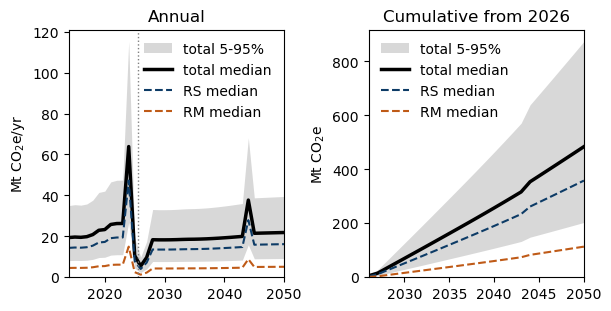

In [116]:
fig, ax = plt.subplots(1, 2, figsize=(6, 3), constrained_layout=True)

for a, df, idx, title, ylab in [(ax[0], annual, years, 'Annual', 'Mt CO$_2$e/yr'),
                                (ax[1], cumulative, years[cum_mask], f'Cumulative from {cum_start}', 'Mt CO$_2$e')]:
    a.fill_between(idx, df['total']['p5'], df['total']['p95'], color='grey', alpha=0.3, lw=0, label='total 5-95%')
    for k in ['total', 'RS', 'RM']:
        a.plot(idx, df[k]['p50'], color=clr[k], lw=2.5 if k == 'total' else 1.5, ls='-' if k == 'total' else '--', label=f'{k} median')
    a.set(title=title, ylabel=ylab, xlim=[idx[0], idx[-1]], ylim=(0, None))
    a.legend(frameon=False)

ax[0].axvline(cum_start - 0.5, color='grey', ls=':', lw=1)